In [4]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
import numpy as np

# Define the dataset path
dataset_path = Path("dataset_8")

# Aggregate all image paths and labels
image_paths = list(dataset_path.glob("*/*.jpg"))
data = [(str(path), path.parent.name) for path in image_paths]
df = pd.DataFrame(data, columns=["filepath", "label"])

# Count class distribution
plt.figure(figsize=(8, 6))
sns.countplot(x='label', data=df, order=df['label'].value_counts().index)
plt.title("Number of Images per Class")
plt.xlabel("Tumor Type")
plt.ylabel("Image Count")
plt.grid(axis='y')
plt.tight_layout()
plt.savefig("output/class_distribution.png") 
plt.close()

In [5]:
import os

root_dir = 'dataset_8'
total_images = 0

# Loop through each subfolder (class)
for subdir in os.listdir(root_dir):
    subdir_path = os.path.join(root_dir, subdir)
    if os.path.isdir(subdir_path):
        image_files = os.listdir(subdir_path)
        num_images = len(image_files)
        total_images += num_images
        print(f"{subdir}: {num_images} images")

print(f"\nTotal images across all classes: {total_images}")

glioma: 120 images
meningioma: 120 images
notumor: 120 images
pituitary: 120 images

Total images across all classes: 480


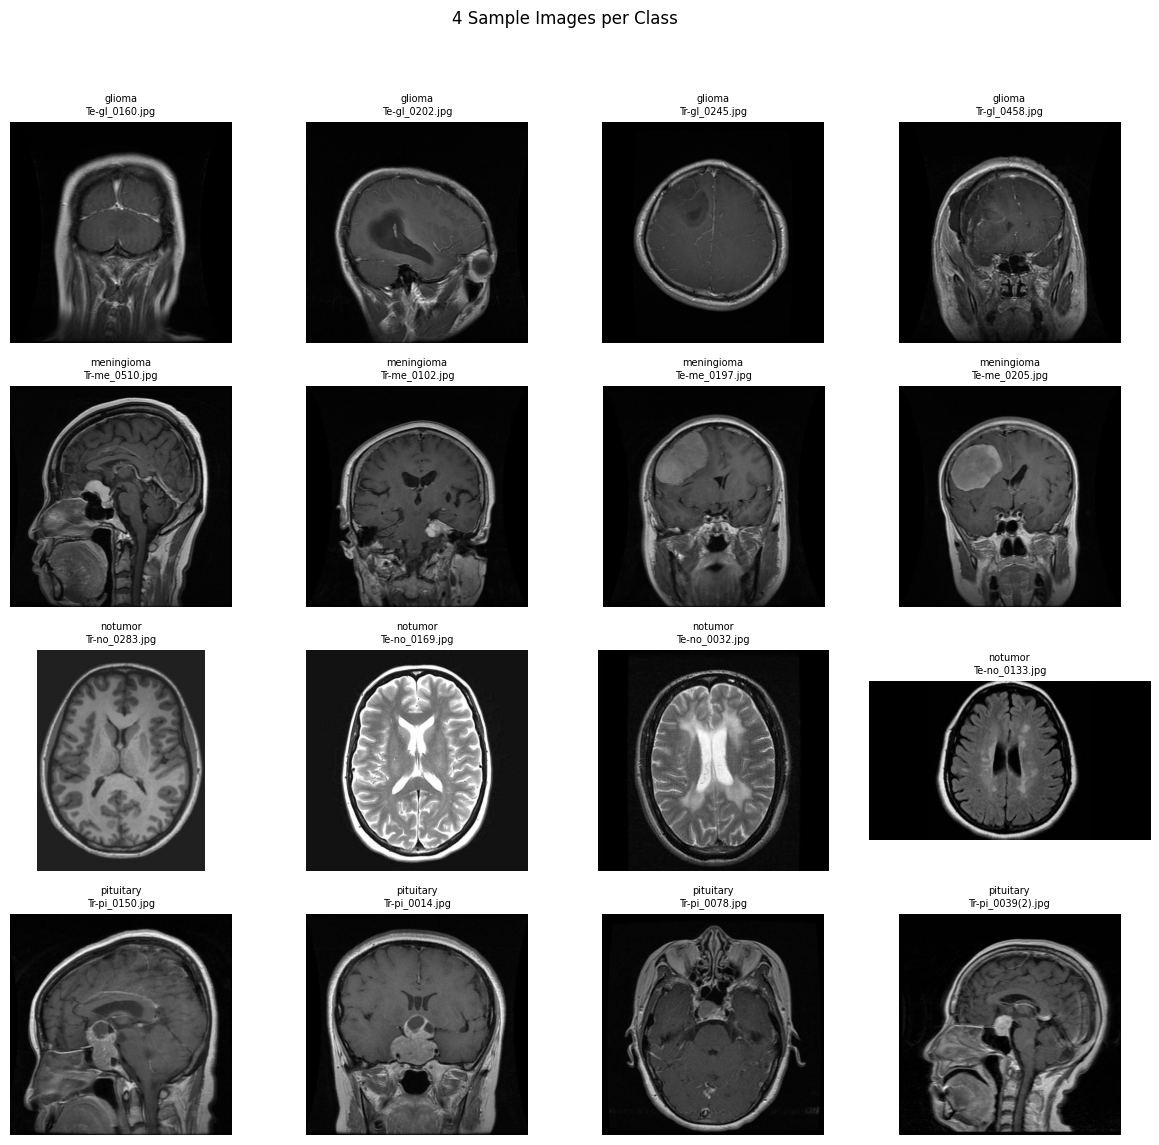

In [6]:
from pathlib import Path
import matplotlib.pyplot as plt
import cv2

def show_all_classes_grid(df):
    class_names = df['label'].unique()
    plt.figure(figsize=(12, 12))

    img_count = 0
    for class_name in class_names:
        class_images = df[df['label'] == class_name]['filepath'].sample(4)
        for img_path in class_images:
            img_path = Path(img_path)
            img = cv2.imread(str(img_path))

            if img is not None:
                img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
                plt.subplot(4, 4, img_count + 1)
                plt.imshow(img)
                plt.title(f"{class_name}\n{img_path.name}", fontsize=7)
                plt.axis('off')
                img_count += 1

            if img_count >= 16:
                break
        if img_count >= 16:
            break

    plt.suptitle("4 Sample Images per Class", fontsize=12)
    plt.tight_layout(rect=[0, 0.03, 1, 0.95])
    plt.show()

show_all_classes_grid(df)


In [7]:
# check image shape

import cv2

# Extract image shapes
df['shape'] = df['filepath'].apply(lambda x: cv2.imread(str(x)).shape if cv2.imread(str(x)) is not None else None)

# Count unique shapes
print(df['shape'].value_counts())


shape
(512, 512, 3)    317
(225, 225, 3)     14
(236, 236, 3)     11
(442, 442, 3)      5
(630, 630, 3)      5
                ... 
(250, 201, 3)      1
(454, 442, 3)      1
(449, 359, 3)      1
(681, 685, 3)      1
(502, 502, 3)      1
Name: count, Length: 106, dtype: int64


dataset has 106 unique image sizes. resize all images during pre-processing (either 512x512 or 224x224)

In [8]:
import numpy as np

def compute_stats(path):
    img = cv2.imread(str(path), cv2.IMREAD_GRAYSCALE)
    return pd.Series({
        'mean_intensity': np.mean(img),
        'std_intensity': np.std(img)
    }) if img is not None else pd.Series({'mean_intensity': None, 'std_intensity': None})

df[['mean_intensity', 'std_intensity']] = df['filepath'].apply(compute_stats)

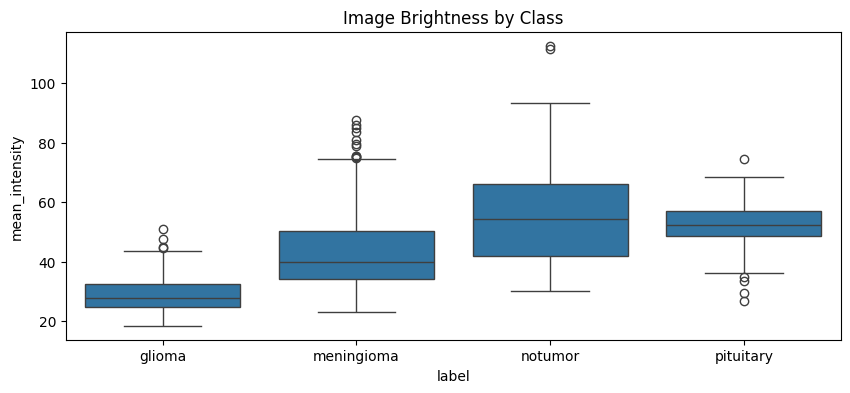

In [ ]:
# image brightness analysis
import seaborn as sns
plt.figure(figsize=(10, 4))
sns.boxplot(x='label', y='mean_intensity', data=df)
plt.title('Image Brightness by Class')
plt.show()

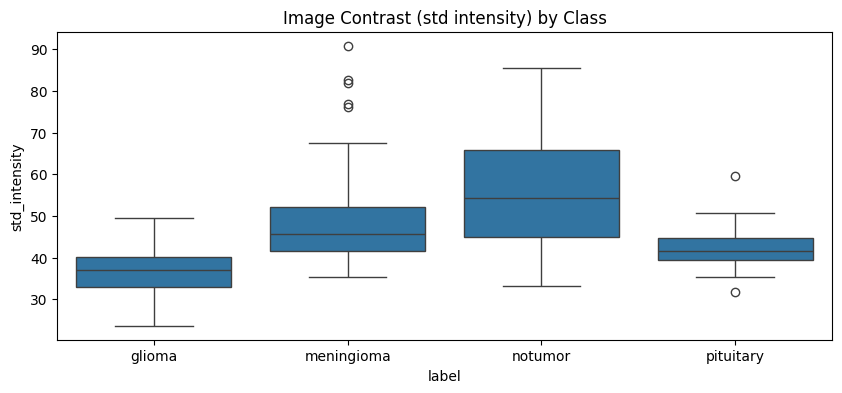

In [ ]:
# image contrast by standard deviation of pixel intensity
import seaborn as sns
plt.figure(figsize=(10, 4))
sns.boxplot(x='label', y='std_intensity', data=df)
plt.title('Image Contrast (std intensity) by Class')
plt.show()

In [12]:
def is_image_valid(path):
    try:
        img = cv2.imread(str(path))
        return img is not None
    except:
        return False

df['valid'] = df['filepath'].apply(is_image_valid)
print(df['valid'].value_counts())


valid
True    480
Name: count, dtype: int64
